# Day 07 — Week 1 Stock Prediction Recap

**End-to-end AAPL stock-direction research pipeline**  
**Default ticker:** `AAPL` · **Prediction target:** next trading session's adjusted-close return direction

This notebook consolidates the most important concepts from Week 1: historical prices, returns, basic statistics, technical-feature engineering, labeled targets, chronological train/test splitting, three model approaches, evaluation, and a next-session probability estimate.

> **How to use this notebook:** edit `TICKER = "AAPL"` in the Configuration cell below. Set it to another supported Yahoo Finance ticker (for example `MSFT`, `NVDA`, `SPY`, or `QQQ`) and run the notebook from top to bottom (**Restart Kernel → Run All** in VS Code). This configuration variable is the ticker input; no extra widget package is required.

**Important:** this is a learning/research pipeline, not investment advice. Daily stock direction is noisy. The displayed probability is a model estimate, not a guarantee or necessarily a calibrated probability. Historical classification accuracy does not establish trading profitability.

## 1. Week 1 recap — what we learned

| Day | Main concepts | Why they matter |
|---|---|---|
| **Day 1 — Market data** | Stock, OHLCV, adjusted prices, Pandas DataFrame, basic price/volume charts, daily return | Understand what each market-data row represents. |
| **Day 2 — Pandas & cleaning** | `DatetimeIndex`, `.loc`, `.iloc`, filtering, sorting, missing values, duplicate dates, CSV I/O | Select and validate historical observations reliably. |
| **Day 3 — Statistics** | Mean, median, percentiles, standard deviation, cumulative return, rolling volatility, correlation | Quantify returns, variation, and relationships between assets. |
| **Day 4 — Features** | SMA, EMA, momentum, RSI, MACD, Bollinger Bands, relative volume | Turn historical observations into numeric input features. |
| **Day 5 — Prediction setup** | Lagged features, future-return target, UP/DOWN label, chronological split, simple baselines | Define exactly what the model knows and what it predicts. |
| **Day 6 — First ML model** | Logistic regression, scaling, `fit`, `predict`, `predict_proba`, classification metrics | Train and evaluate a model on later, held-out observations. |

### Key finance concepts

- **OHLCV:** Open, High, Low, Close, and Volume for a market-data bar.
- **Return:** percentage change between two prices, such as `price_t / price_(t-1) - 1`.
- **Cumulative return:** compounded return across a sequence, not the sum of daily returns.
- **Volatility:** variability of returns, often measured with standard deviation.
- **Correlation:** strength and direction of a linear relationship; it does not prove causation or predictive usefulness.
- **Technical indicator:** a transformation of historical prices/volume. It is a possible feature, not an automatic buy/sell signal.

### Key data/ML concepts

- **Feature (`X`):** inputs that would be available at prediction time.
- **Target (`y`):** future outcome being predicted.
- **Lag:** a past observation aligned to a later row with `shift(1)`, `shift(5)`, etc.
- **Future target:** `shift(-1)` can align the next observation with the current row, which is appropriate for creating a future label—but not for creating an input feature.
- **Chronological split:** train on earlier examples and test on later examples.
- **Leakage:** information that would not have been available at prediction time sneaks into inputs or model selection.
- **Baseline:** a simple rule that gives us a reference score to beat.
- **Accuracy is not profitability:** trading costs, slippage, gains/losses, execution timing, exposure, and drawdowns matter too.

## 2. The three approaches compared in this notebook

These are the **two Week 1 baselines plus the first learned ML model**:

1. **Majority-class baseline** — `DummyClassifier(strategy="most_frequent")`. Learns which label (UP or DOWN/non-positive) is more common in the training set and predicts that class every time. It deliberately ignores the features. This helps reveal whether apparent accuracy comes simply from class frequency.
2. **Direction-persistence baseline** — predicts that today's direction repeats: if today's daily return is positive, predict UP for the next session; otherwise predict DOWN/non-positive. It is a simple rule, not a trained ML algorithm.
3. **Logistic regression** — a supervised classification model. It learns coefficients from training examples and estimates the probability that the next-session return is positive. We standardize features in a pipeline so the scaler is fitted on training data only.

**Why compare them?** Complexity only helps if it improves on a sensible baseline in out-of-sample testing. Results below are calculated from the ticker you enter; no results are hard-coded.

## 3. Setup and imports

Install dependencies in the VS Code terminal from the project root if needed:

```powershell
.\.venv\Scripts\python.exe -m pip install yfinance pandas numpy matplotlib scikit-learn
```

The notebook uses `Ticker.history(..., auto_adjust=True)`, so the downloaded OHLC prices are automatically adjusted by yfinance. We use its `Close` column consistently for price-derived calculations. Yahoo Finance data is convenient for learning, but should not be treated as a guaranteed institutional-grade data feed.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    classification_report,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print("Imports ready.")

Imports ready.


## 4. User input — choose a ticker

Change `TICKER` to another ticker symbol, then run all cells. `HISTORY_PERIOD = "10y"` requests up to ten years of daily history, subject to data availability. The model predicts the direction from the latest completed observation to the next trading session in the downloaded data.

In [3]:
# USER INPUT: edit this value, then select Restart Kernel -> Run All.
TICKER = "NVDA"             # Examples: "MSFT", "NVDA", "SPY", "QQQ"
HISTORY_PERIOD = "10y"       # yfinance-supported period, e.g. "5y" or "10y"
TRAIN_FRACTION = 0.80        # first 80% train, last 20% test
RANDOM_STATE = 42

TICKER = TICKER.strip().upper()
if not TICKER:
    raise ValueError("TICKER cannot be blank.")
if not 0.50 <= TRAIN_FRACTION <= 0.90:
    raise ValueError("Choose a TRAIN_FRACTION between 0.50 and 0.90.")

print(f"Ticker: {TICKER}")
print(f"History period: {HISTORY_PERIOD}")
print(f"Chronological training fraction: {TRAIN_FRACTION:.0%}")

Ticker: NVDA
History period: 10y
Chronological training fraction: 80%


## 5. Download and inspect OHLCV data (Day 1–2)

A row is one daily bar; the index records the trading date. Because `auto_adjust=True`, this notebook uses the adjusted `Close` field for returns and indicators. The history request uses daily data and excludes pre/post-market bars.

In [4]:
price_data = yf.Ticker(TICKER).history(
    period=HISTORY_PERIOD,
    interval="1d",
    prepost=False,
    auto_adjust=True,
    actions=False,
)

if price_data.empty:
    raise ValueError(
        f"No price data returned for {TICKER}. Check the symbol, internet connection, "
        "or Yahoo Finance data availability."
    )

required_columns = ["Open", "High", "Low", "Close", "Volume"]
missing_columns = [col for col in required_columns if col not in price_data.columns]
if missing_columns:
    raise ValueError(f"Downloaded data is missing required columns: {missing_columns}")

# Keep and order the columns used by this project.
df = price_data[required_columns].copy().sort_index()
df = df.loc[~df.index.duplicated(keep="first")]
df = df.dropna(subset=["Close"])
df.index.name = "Date"

if len(df) < 260:
    raise ValueError(
        f"Only {len(df)} rows were returned. A longer history is needed because the "
        "200-day moving average requires sufficient observations. Try a longer period."
    )

print(f"Downloaded {len(df):,} daily rows for {TICKER}.")
print(f"First date: {df.index.min()}")
print(f"Last date:  {df.index.max()}")
display(df.head())
display(df.describe().T)

Downloaded 2,514 daily rows for NVDA.
First date: 2016-10-10 00:00:00-04:00
Last date:  2026-10-09 00:00:00-04:00


,Open,High,Low,Close,Volume
Date,,,,,
2016-10-10 00:00:00-04:00,1.648607,1.657439,1.630698,1.646154,287876000
2016-10-11 00:00:00-04:00,1.640757,1.643210,1.609845,1.622357,388540000
2016-10-12 00:00:00-04:00,1.615733,1.638303,1.602240,1.629717,419920000
2016-10-13 00:00:00-04:00,1.610581,1.614261,1.562742,1.603222,390116000
2016-10-14 00:00:00-04:00,1.622847,1.633887,1.609354,1.618922,330636000


,count,mean,std,min,25%,50%,75%,max
Open,2514.0,5.150881e+01,6.665366e+01,1.610581e+00,5.601825e+00,1.596943e+01,8.801628e+01,2.421000e+02
High,2514.0,5.232871e+01,6.758991e+01,1.614261e+00,5.684257e+00,1.630082e+01,9.006744e+01,2.433700e+02
Low,2514.0,5.060041e+01,6.557644e+01,1.562742e+00,5.460326e+00,1.564169e+01,8.633034e+01,2.389300e+02
Close,2514.0,5.148585e+01,6.657638e+01,1.603222e+00,5.563864e+00,1.603494e+01,8.789088e+01,2.392400e+02
Volume,2514.0,4.405256e+08,2.640556e+08,6.552850e+07,2.565671e+08,3.978795e+08,5.513558e+08,3.692928e+09


## 6. Price, return and volatility recap (Day 1 & Day 3)

A daily return is `Close.pct_change()`. Its average describes the sample's arithmetic mean daily return; its standard deviation describes historical dispersion. Annualized volatility is a conventional approximation using `sqrt(252)` trading days—not a prediction of future risk.

,Value
Mean daily return (%),0.2459
Median daily return (%),0.2648
Daily volatility (%),3.1532
Approx. annualized volatility (%),50.0552
1st percentile daily return (%),-7.6580
99th percentile daily return (%),7.9741


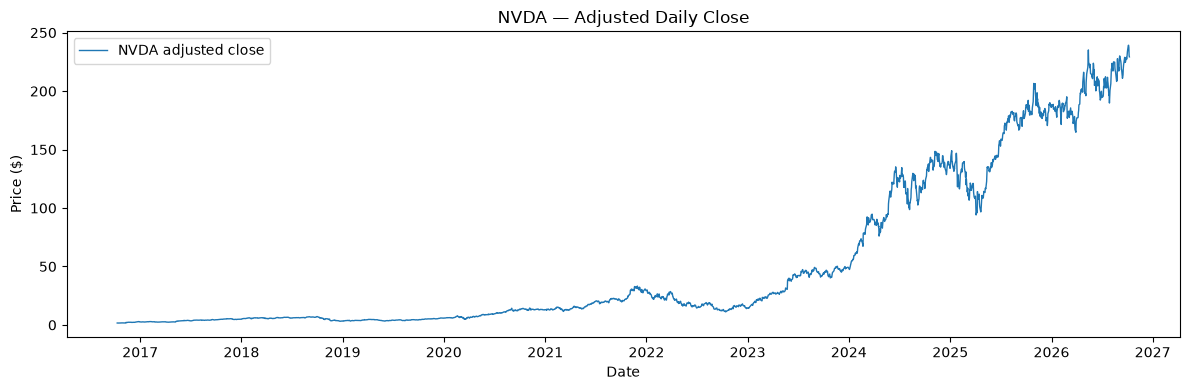

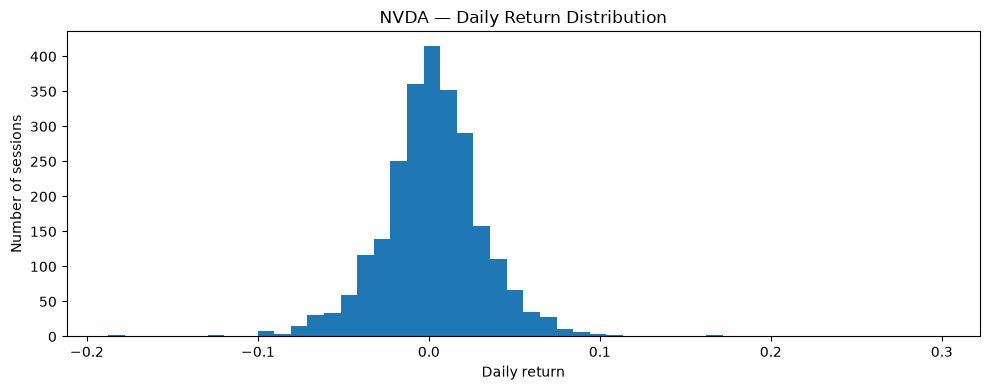

In [5]:
df["daily_return"] = df["Close"].pct_change()
returns = df["daily_return"].dropna()

stats = pd.Series({
    "Mean daily return (%)": returns.mean() * 100,
    "Median daily return (%)": returns.median() * 100,
    "Daily volatility (%)": returns.std() * 100,
    "Approx. annualized volatility (%)": returns.std() * np.sqrt(252) * 100,
    "1st percentile daily return (%)": returns.quantile(0.01) * 100,
    "99th percentile daily return (%)": returns.quantile(0.99) * 100,
})
display(stats.to_frame("Value").round(4))

plt.figure(figsize=(12, 4))
plt.plot(df.index, df["Close"], label=f"{TICKER} adjusted close", linewidth=1)
plt.title(f"{TICKER} — Adjusted Daily Close")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(returns, bins=50)
plt.title(f"{TICKER} — Daily Return Distribution")
plt.xlabel("Daily return")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

## 7. Market context: correlation with SPY and QQQ (Day 3)

AAPL can move with the broader market, so Week 1 also compared the chosen ticker's daily returns with SPY (broad S&P 500 ETF) and QQQ (Nasdaq-100 ETF). This optional cell fetches those two reference series and calculates return correlations. Correlation describes a linear association; it does not establish causation or reliable prediction. If a reference download fails, the main modeling pipeline can still continue.

In [6]:
context_returns = {TICKER: df["daily_return"].rename(TICKER)}

for symbol in ["SPY", "QQQ"]:
    if symbol == TICKER:
        continue
    try:
        context = yf.Ticker(symbol).history(
            period=HISTORY_PERIOD, interval="1d", prepost=False,
            auto_adjust=True, actions=False
        )
        if not context.empty and "Close" in context.columns:
            context_returns[symbol] = context["Close"].pct_change().rename(symbol)
        else:
            print(f"No reference data returned for {symbol}; skipping it.")
    except Exception as exc:
        print(f"Could not load {symbol} for correlation context: {exc}")

market_returns = pd.concat(context_returns.values(), axis=1).dropna()
if market_returns.shape[1] > 1 and len(market_returns) > 20:
    display(market_returns.corr().round(3))
    ticker_correlations = market_returns.corr()[TICKER].drop(labels=[TICKER], errors="ignore")
    print(f"Return correlations with {TICKER} (historical sample):")
    display(ticker_correlations.sort_values(ascending=False).to_frame("correlation"))
else:
    print("Not enough overlapping return data to calculate market-context correlations.")

,NVDA,SPY,QQQ
NVDA,1.000,0.658,0.752
SPY,0.658,1.000,0.932
QQQ,0.752,0.932,1.000


Return correlations with NVDA (historical sample):


,correlation
QQQ,0.751898
SPY,0.658317


## 7. Feature engineering (Day 4)

We create a small, reusable selection of the most important Week 1 features. The calculations use the current and previous observations only. `rolling()` creates window-based statistics; `ewm()` calculates exponential moving averages; `shift(1)` creates past-return features.

In [7]:
# Trend features
for window in (20, 50, 200):
    df[f"SMA_{window}"] = df["Close"].rolling(window).mean()

df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()
df["EMA_26"] = df["Close"].ewm(span=26, adjust=False).mean()
df["price_to_SMA20"] = df["Close"] / df["SMA_20"] - 1
df["SMA20_to_SMA50"] = df["SMA_20"] / df["SMA_50"] - 1

# Momentum, lagged returns and volatility
df["momentum_10d"] = df["Close"] / df["Close"].shift(10) - 1
df["return_lag_1"] = df["daily_return"].shift(1)
df["return_lag_5"] = df["daily_return"].shift(5)
df["rolling_20d_volatility"] = df["daily_return"].rolling(20).std()

# RSI-14 using exponentially smoothed average gains and losses
delta = df["Close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
avg_loss = loss.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
rs = avg_gain / avg_loss.replace(0, np.nan)
df["RSI_14"] = 100 - (100 / (1 + rs))
df.loc[(avg_loss == 0) & (avg_gain > 0), "RSI_14"] = 100
df.loc[(avg_gain == 0) & (avg_loss > 0), "RSI_14"] = 0

# MACD (12, 26, 9)
df["MACD"] = df["EMA_12"] - df["EMA_26"]
df["MACD_signal"] = df["MACD"].ewm(span=9, adjust=False).mean()
df["MACD_hist"] = df["MACD"] - df["MACD_signal"]

# Bollinger Bands: 20-day average +/- 2 rolling standard deviations
rolling_std_20 = df["Close"].rolling(20).std()
df["BB_upper"] = df["SMA_20"] + 2 * rolling_std_20
df["BB_lower"] = df["SMA_20"] - 2 * rolling_std_20
band_width = (df["BB_upper"] - df["BB_lower"]).replace(0, np.nan)
df["BB_percent_b"] = (df["Close"] - df["BB_lower"]) / band_width

# Relative volume compares today's volume with its recent average
df["volume_change"] = df["Volume"].pct_change()
df["volume_SMA20"] = df["Volume"].rolling(20).mean()
df["relative_volume"] = df["Volume"] / df["volume_SMA20"]

df = df.replace([np.inf, -np.inf], np.nan)

FEATURE_COLUMNS = [
    "daily_return", "return_lag_1", "return_lag_5",
    "rolling_20d_volatility", "SMA_20", "SMA_50", "SMA_200",
    "EMA_12", "EMA_26", "price_to_SMA20", "SMA20_to_SMA50",
    "momentum_10d", "RSI_14", "MACD", "MACD_signal", "MACD_hist",
    "BB_percent_b", "volume_change", "relative_volume",
]

print(f"Created {len(FEATURE_COLUMNS)} features.")
display(df[FEATURE_COLUMNS].tail())

Created 19 features.


,daily_return,return_lag_1,return_lag_5,rolling_20d_volatility,SMA_20,SMA_50,SMA_200,EMA_12,EMA_26,price_to_SMA20,SMA20_to_SMA50,momentum_10d,RSI_14,MACD,MACD_signal,MACD_hist,BB_percent_b,volume_change,relative_volume
Date,,,,,,,,,,,,,,,,,,,
2026-10-05 00:00:00-04:00,0.021158,0.013385,0.016839,0.016039,224.187885,218.764908,200.687061,228.890262,224.668265,0.065624,0.024789,0.050664,67.010158,4.221997,3.019010,1.202987,1.016624,-0.059158,1.160780
2026-10-06 00:00:00-04:00,0.001423,0.021158,-0.007210,0.015178,224.876000,219.623901,201.030556,230.482530,225.747653,0.063875,0.023914,0.045310,67.271905,4.734877,3.362184,1.372694,0.955970,-0.200278,0.937399
2026-10-07 00:00:00-04:00,-0.007398,0.001423,0.005149,0.015109,225.578500,220.437505,201.349239,231.557526,226.615975,0.052716,0.023322,0.053035,64.407061,4.941551,3.678057,1.263494,0.855987,-0.195960,0.754117
2026-10-08 00:00:00-04:00,-0.029435,-0.007398,0.010859,0.015781,226.184500,221.251152,201.598801,231.391752,226.902199,0.018991,0.022298,0.026271,54.530715,4.489553,3.840356,0.649197,0.630345,0.451558,1.088158
2026-10-09 00:00:00-04:00,-0.005207,-0.029435,0.013385,0.015870,226.734000,221.940313,201.828896,231.066867,227.078332,0.011229,0.021599,0.018705,53.027399,3.988535,3.869992,0.118543,0.579081,-0.288358,0.776011


### Quick feature plots

Moving averages smooth price; momentum measures a past price change; RSI and MACD summarize price momentum in different ways; Bollinger %B locates price relative to the bands; relative volume compares today's activity with its recent average. **None is automatically predictive.** We test features through later-date evaluation.

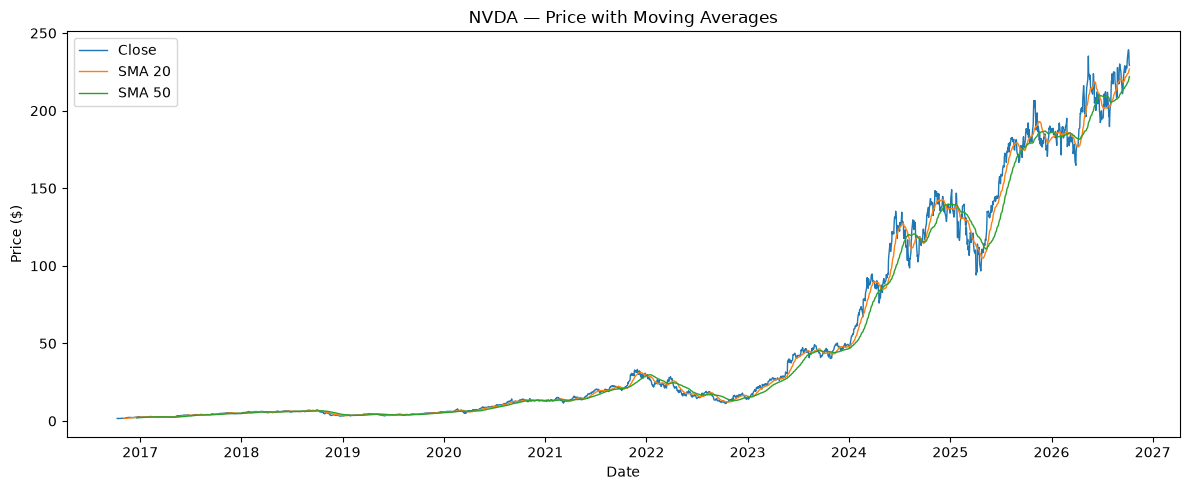

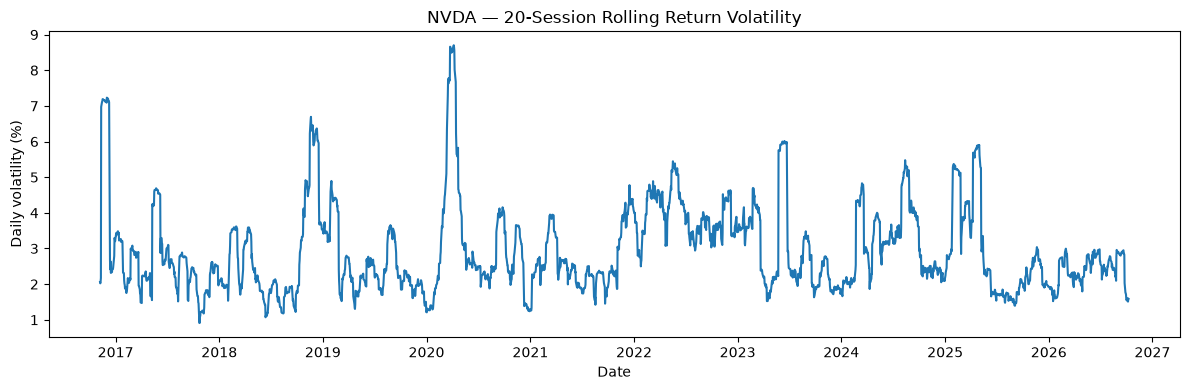

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Close"], label="Close", linewidth=1)
plt.plot(df.index, df["SMA_20"], label="SMA 20", linewidth=1)
plt.plot(df.index, df["SMA_50"], label="SMA 50", linewidth=1)
plt.title(f"{TICKER} — Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(df.index, df["rolling_20d_volatility"] * 100)
plt.title(f"{TICKER} — 20-Session Rolling Return Volatility")
plt.xlabel("Date")
plt.ylabel("Daily volatility (%)")
plt.tight_layout()
plt.show()

## 8. Build the future target (Day 5)

For a row dated session `t`, the target is the return from `Close[t]` to the next available trading session's close. It is aligned with `shift(-1)`. The final row is missing because the next close is not in the dataset.

We define `target_up = 1` when the following session's return is positive and `0` when it is zero or negative. This is a close-to-next-close research target; it does **not** assume an executable trade can be placed at the same closing price used to form the signal.

In [9]:
df["future_return_1d"] = df["Close"].shift(-1) / df["Close"] - 1

df["target_up"] = np.nan
valid_target = df["future_return_1d"].notna()
df.loc[valid_target, "target_up"] = (
    df.loc[valid_target, "future_return_1d"] > 0
).astype(int)

MODEL_COLUMNS = FEATURE_COLUMNS + ["future_return_1d", "target_up"]
model_data = df[MODEL_COLUMNS].dropna().copy()
model_data["target_up"] = model_data["target_up"].astype(int)
model_data = model_data.sort_index()

if len(model_data) < 300:
    raise ValueError("Not enough labeled observations after feature creation; choose a longer history.")
if model_data["target_up"].nunique() < 2:
    raise ValueError("The labeled dataset contains only one class; classification needs both UP and non-UP examples.")

print("Labeled observations:", f"{len(model_data):,}")
print("First labeled date:", model_data.index.min())
print("Last labeled date:", model_data.index.max())
print("UP frequency:", f"{model_data['target_up'].mean():.2%}")
print("Non-UP frequency:", f"{1 - model_data['target_up'].mean():.2%}")
display(model_data[["future_return_1d", "target_up"]].tail())

Labeled observations: 2,314
First labeled date: 2017-07-26 00:00:00-04:00
Last labeled date: 2026-10-08 00:00:00-04:00
UP frequency: 53.89%
Non-UP frequency: 46.11%


,future_return_1d,target_up
Date,,
2026-10-02 00:00:00-04:00,0.021158,1
2026-10-05 00:00:00-04:00,0.001423,1
2026-10-06 00:00:00-04:00,-0.007398,0
2026-10-07 00:00:00-04:00,-0.029435,0
2026-10-08 00:00:00-04:00,-0.005207,0


## 9. Chronological train/test split

The earliest 80% of labeled rows form the training set; the latest 20% form the holdout test set. We do not shuffle time series randomly. The test scores below measure the trained model on later observations, not on its training data.

This simple split is an introductory evaluation. For stronger research, later weeks will introduce walk-forward validation, threshold selection using validation data, and more rigorous handling of model-selection bias.

In [10]:
split_index = int(len(model_data) * TRAIN_FRACTION)
train = model_data.iloc[:split_index].copy()
test = model_data.iloc[split_index:].copy()

X_train = train[FEATURE_COLUMNS]
y_train = train["target_up"].astype(int)
X_test = test[FEATURE_COLUMNS]
y_test = test["target_up"].astype(int)

if y_train.nunique() < 2:
    raise ValueError("Training data has one target class; cannot fit logistic regression.")

print(f"Train: {len(train):,} rows | {train.index.min()} to {train.index.max()}")
print(f"Test:  {len(test):,} rows | {test.index.min()} to {test.index.max()}")
print("Training class fractions:")
display(y_train.value_counts(normalize=True).rename(index={0: "DOWN / non-positive", 1: "UP"}).to_frame("fraction"))

assert train.index.max() < test.index.min(), "Train/test periods overlap."
assert "future_return_1d" not in FEATURE_COLUMNS
assert "target_up" not in FEATURE_COLUMNS
print("Basic chronological split and target-exclusion checks passed.")

Train: 1,851 rows | 2017-07-26 00:00:00-04:00 to 2024-12-02 00:00:00-05:00
Test:  463 rows | 2024-12-03 00:00:00-05:00 to 2026-10-08 00:00:00-04:00
Training class fractions:


,fraction
target_up,
UP,0.54295
DOWN / non-positive,0.45705


Basic chronological split and target-exclusion checks passed.


## 10. Train the three approaches

- **Model 1 — Majority baseline:** predicts the most common class in the training set, ignoring inputs.
- **Model 2 — Direction-persistence baseline:** predicts that the current daily return sign repeats in the next session. It is a rule, not a learned classifier.
- **Model 3 — Logistic regression:** learns from training data. Scaling is fitted only within the training pipeline.

The three approaches are compared on precisely the same test dates.

In [11]:
# Model 1: Majority-class baseline
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)
majority_predictions = majority_model.predict(X_test)

# Model 2: Previous-session direction-persistence rule
persistence_predictions = (test["daily_return"] > 0).astype(int).to_numpy()

# Model 3: Scaled logistic regression
logistic_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)
classifier = logistic_model.named_steps["classifier"]
up_class_index = list(classifier.classes_).index(1)
probability_up_test = logistic_probabilities[:, up_class_index]

print("All three approaches evaluated on the same holdout dates.")

All three approaches evaluated on the same holdout dates.


## 11. Compare test performance

Accuracy is the proportion of correct classifications. Balanced accuracy averages recall across classes. Precision (UP) asks, “Of observations predicted UP, what fraction were UP?” Recall (UP) asks, “Of the actual UP observations, what fraction did we identify?” F1 balances precision and recall. ROC-AUC uses probability scores to measure ranking performance and is only reported for logistic regression here.

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(name, y_true, y_pred, probability_up=None):
    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision (UP)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (UP)": recall_score(y_true, y_pred, zero_division=0),
        "F1 (UP)": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": np.nan,
    }
    if probability_up is not None and pd.Series(y_true).nunique() == 2:
        result["ROC-AUC"] = roc_auc_score(y_true, probability_up)
    return result

results = pd.DataFrame([
    evaluate_model("1. Majority baseline", y_test, majority_predictions),
    evaluate_model("2. Direction persistence", y_test, persistence_predictions),
    evaluate_model("3. Logistic regression", y_test, logistic_predictions, probability_up_test),
]).set_index("Model")

display(results.style.format("{:.2%}", na_rep="N/A"))

,Accuracy,Balanced accuracy,Precision (UP),Recall (UP),F1 (UP),ROC-AUC
Model,,,,,,
1. Majority baseline,52.27%,50.00%,52.27%,100.00%,68.65%,N/A
2. Direction persistence,48.81%,48.70%,51.03%,51.24%,51.13%,N/A
3. Logistic regression,52.48%,50.23%,52.38%,100.00%,68.75%,52.23%


### Accuracy chart — compare all three approaches

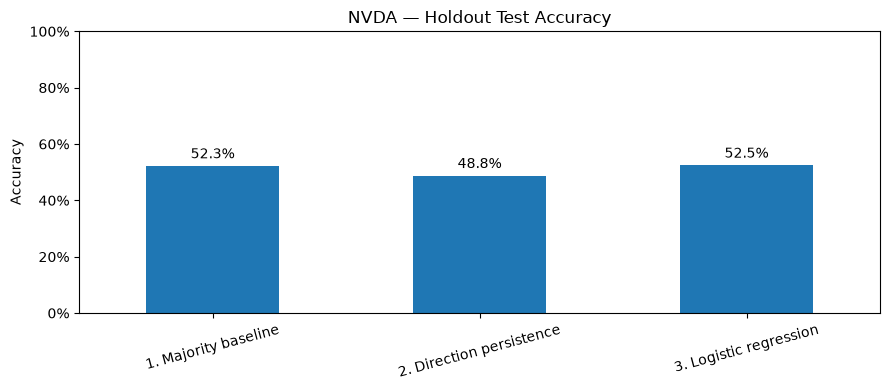

In [13]:
from matplotlib.ticker import PercentFormatter

ax = results["Accuracy"].plot(kind="bar", figsize=(9, 4), ylim=(0, 1), rot=15)
ax.set_title(f"{TICKER} — Holdout Test Accuracy")
ax.set_ylabel("Accuracy")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
for container in ax.containers:
    labels = [f"{value:.1%}" for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)
plt.tight_layout()
plt.show()

### Inspect classification errors for logistic regression

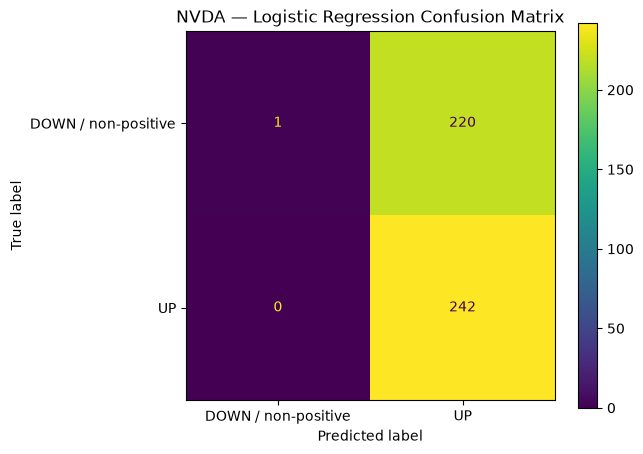

                     precision    recall  f1-score   support

DOWN / non-positive       1.00      0.00      0.01       221
                 UP       0.52      1.00      0.69       242

           accuracy                           0.52       463
          macro avg       0.76      0.50      0.35       463
       weighted avg       0.75      0.52      0.36       463



In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    labels=[0, 1],
    display_labels=["DOWN / non-positive", "UP"],
    values_format="d",
)
plt.title(f"{TICKER} — Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    logistic_predictions,
    labels=[0, 1],
    target_names=["DOWN / non-positive", "UP"],
    zero_division=0,
))

## 12. Review individual test predictions

This table puts the predicted label and probability beside the outcome that followed that historical prediction date. It is useful for inspecting model behavior, but a few rows do not establish a reliable pattern.

In [15]:
test_predictions = pd.DataFrame({
    "Actual direction": y_test.map({0: "DOWN / non-positive", 1: "UP"}),
    "Predicted direction": pd.Series(logistic_predictions, index=test.index).map(
        {0: "DOWN / non-positive", 1: "UP"}
    ),
    "Estimated probability UP": probability_up_test,
    "Realized next-session return": test["future_return_1d"],
}, index=test.index)

display(test_predictions.tail(15))

,Actual direction,Predicted direction,Estimated probability UP,Realized next-session return
Date,,,,
2026-09-18 00:00:00-04:00,UP,UP,0.671339,0.022990
2026-09-21 00:00:00-04:00,UP,UP,0.650596,0.006553
2026-09-22 00:00:00-04:00,DOWN / non-positive,UP,0.664767,-0.014681
2026-09-23 00:00:00-04:00,DOWN / non-positive,UP,0.666487,-0.004124
2026-09-24 00:00:00-04:00,UP,UP,0.647332,0.002182
2026-09-25 00:00:00-04:00,UP,UP,0.663870,0.016839
2026-09-28 00:00:00-04:00,DOWN / non-positive,UP,0.668935,-0.007210
2026-09-29 00:00:00-04:00,UP,UP,0.686541,0.005149
2026-09-30 00:00:00-04:00,UP,UP,0.666258,0.010859


## 13. Feature/target correlation (training period only)

This repeats a Day 5 exploration: correlation between each feature and the subsequent return. Treat this as a descriptive check, not as proof of predictive power. Correlation may miss nonlinear relationships and can be unstable over time.

In [16]:
feature_target_corr = train[FEATURE_COLUMNS].corrwith(train["future_return_1d"])
corr_summary = pd.DataFrame({
    "Correlation with next-session return": feature_target_corr,
    "Absolute correlation": feature_target_corr.abs(),
}).sort_values("Absolute correlation", ascending=False)

display(corr_summary.head(10))

,Correlation with next-session return,Absolute correlation
daily_return,-0.078495,0.078495
return_lag_1,0.027752,0.027752
return_lag_5,-0.027438,0.027438
price_to_SMA20,-0.019539,0.019539
relative_volume,0.018743,0.018743
momentum_10d,-0.014957,0.014957
SMA_50,0.012204,0.012204
SMA_200,0.011506,0.011506
EMA_26,0.011085,0.011085
SMA_20,0.011039,0.011039


## 14. Latest next-session estimate

For a current estimate, we fit a fresh logistic regression pipeline on **all currently labeled history** and use the latest date with complete features to estimate the direction for the next trading session.

This is a different use from the holdout test: the test metrics above were calculated on later observations not used to fit the test model; this final refit is for a current illustrative estimate. Do not use the refitted model's output to claim additional test accuracy. The probability is not guaranteed to be calibrated, and this notebook does not model realistic trade execution.

In [17]:
final_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
final_model.fit(model_data[FEATURE_COLUMNS], model_data["target_up"].astype(int))

latest_feature_rows = df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan).dropna()
if latest_feature_rows.empty:
    raise ValueError("No latest row has all required features. Try a longer history period.")

latest_X = latest_feature_rows.iloc[[-1]]
latest_date = latest_X.index[-1]
latest_close = df.loc[latest_date, "Close"]
next_prediction = int(final_model.predict(latest_X)[0])
next_probabilities = final_model.predict_proba(latest_X)[0]
final_classifier = final_model.named_steps["classifier"]
final_up_index = list(final_classifier.classes_).index(1)
next_probability_up = float(next_probabilities[final_up_index])
next_probability_down = 1.0 - next_probability_up

print(f"Ticker: {TICKER}")
print(f"Latest available feature date: {latest_date}")
print(f"Latest adjusted close: ${latest_close:,.2f}")
print("Forecast horizon: next trading session, close-to-close direction")
print(f"Estimated probability UP:   {next_probability_up:.2%}")
print(f"Estimated probability DOWN/non-positive: {next_probability_down:.2%}")
print("Predicted class:", "UP" if next_prediction == 1 else "DOWN / non-positive")
print("\nFor context only — holdout logistic regression accuracy:", f"{results.loc['3. Logistic regression', 'Accuracy']:.2%}")

Ticker: NVDA
Latest available feature date: 2026-10-09 00:00:00-04:00
Latest adjusted close: $229.28
Forecast horizon: next trading session, close-to-close direction
Estimated probability UP:   50.11%
Estimated probability DOWN/non-positive: 49.89%
Predicted class: UP

For context only — holdout logistic regression accuracy: 52.48%


## 15. What the results mean — and don't mean

- **Holdout accuracy** measures the fraction of correctly classified labels in the chosen historical test period.
- **Estimated UP probability** is the current model's estimate for the next session. It is not the historical accuracy and does not mean the model is this percentage “sure.”
- **Beating a baseline is a first check, not proof of an edge.** Compare across time periods and use walk-forward tests in a later phase.
- **This is not a backtest.** It does not simulate order timing, transaction fees, slippage, position sizing, portfolio exposure, or realized trade P&L.
- **Data quality matters.** This uses historical data obtained through yfinance/Yahoo Finance. Confirm data availability, corporate-action handling, and adjusted-price assumptions before drawing conclusions.